#### Impoertant Question:

    what happends when the amplitude of the reference signal changes significantly?

We now that if we keep step size unchanged, the LMS update can become much larger because it is multiplied by x[n] ( w = w + mu * e[n] * x_ref[n] )

This means that stability and adaptation behavior of the LMS depend on the power of the reference signal, not just the step size.

Here, we can investigate what NLMS does.
    
    NLMS devides the coefficients update by a measure of the referenec signal's power

NLMS adjusts the effective step size according to the reference magnitude. This makes adaptation less sensitive to changes in reference power.

Keep in mind that, it does not eliminate every fluctuation or guarrantee better performance in every situation.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

fs, duration = 200, 5
N = fs * duration
t = np.arange(N) / fs

clean = np.sin(2 * np.pi * 1 * t) + 0.4 * np.sin(2 * np.pi * 3 * t)

ref_amplitude = np.where(t < 2.5, 0.2, 2.0)
x_ref = ref_amplitude * np.sin(2 *np.pi * 65 * t)
d = clean + 0.6 * x_ref

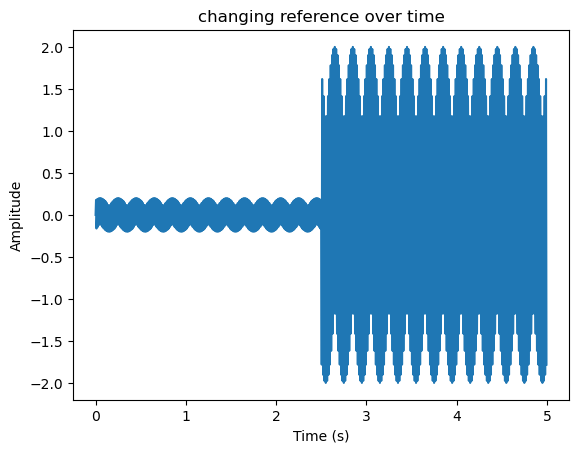

In [16]:
# Plotting x_ref over the entire duration
plt.plot(t, x_ref)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("changing reference over time")
plt.show()

#### Applying ordinary LMS

From the noisy measurement (d) we know that the ideal coefficient we want LMS to learn is 0.6

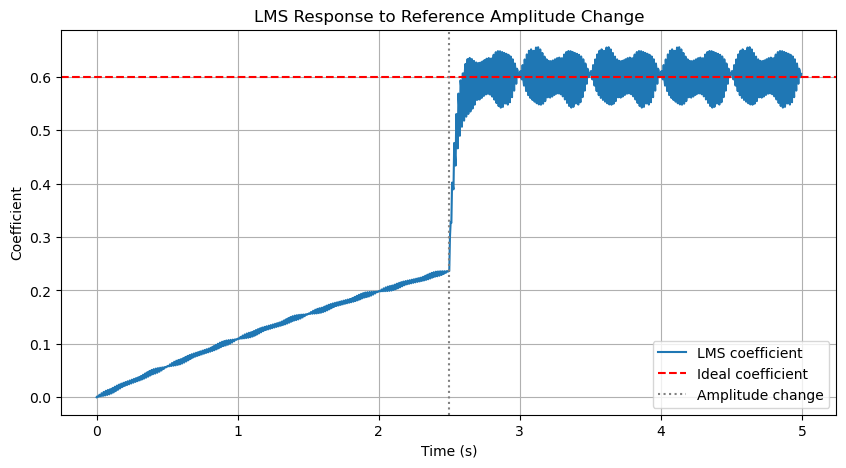

In [17]:
mu = 0.05
w = 0.0
y_lms = np.zeros(N)
e_lms = np.zeros(N)
w_history_lms = np.zeros(N)
for n in range(N):
    y_lms[n] = w * x_ref[n]
    e_lms[n] = d[n] - y_lms[n]
    w = w + mu * e_lms[n] * x_ref[n]
    w_history_lms[n] = w

plt.figure(figsize=(10, 5))
plt.plot(t, w_history_lms, label="LMS coefficient")
plt.axhline(0.6, color="red", linestyle="--", label="Ideal coefficient")
plt.axvline(2.5, color="gray", linestyle=":", label="Amplitude change")
plt.xlabel("Time (s)")
plt.ylabel("Coefficient")
plt.title("LMS Response to Reference Amplitude Change")
plt.legend()
plt.grid(True)
plt.show()

#### VERY IMPORTANT:

0-2.5 s (small reference amplitude 0.2):

    The coefficient increases very slowly, reaching only about 2.4 instead of the ideal 0.6

2.5-5 s (large reference amplitude 2.0):

    The coefficient quickly approaches 0.6, but then fluctuates noticeably around it

This reveals two limitations of ordinary LMS with a fixed step size:

    1- With small reference signal, adaptation can be very slow.
    2- With large signal, adaptation becomes faster, but coefficient fluctuations can increase

#### Applying NLMS

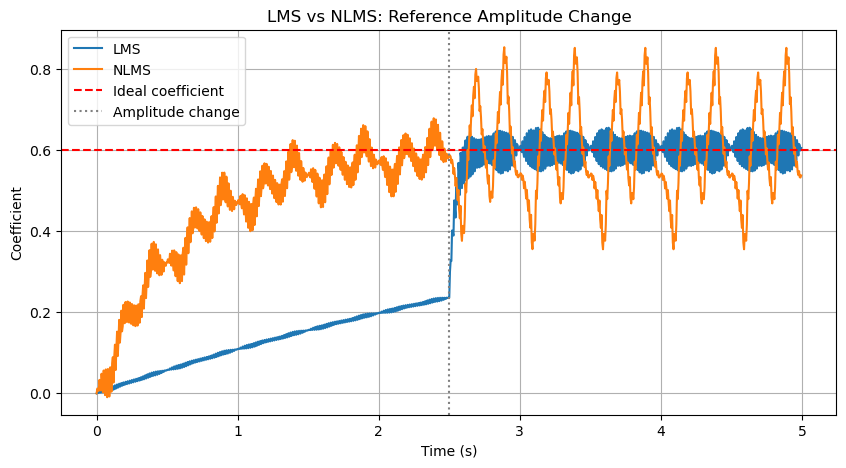

In [20]:
mu = 0.05
epsilon = 0.1      #epsilon prevents devision by zero
w = 0.0
y_nlms = np.zeros(N)
e_nlms = np.zeros(N)
w_history_nlms = np.zeros(N)

for n in range(N):
    y_nlms[n] = w * x_ref[n]
    e_nlms[n] = d[n] - y_nlms[n]
    w = w + (mu * e_nlms[n] * x_ref[n]) / (epsilon + x_ref[n] ** 2)
    w_history_nlms[n] = w

plt.figure(figsize=(10, 5))
plt.plot(t, w_history_lms, label="LMS")
plt.plot(t, w_history_nlms, label="NLMS")
plt.axhline(0.6, color="red", linestyle="--",
            label="Ideal coefficient")
plt.axvline(2.5, color="gray", linestyle=":",
            label="Amplitude change")
plt.xlabel("Time (s)")
plt.ylabel("Coefficient")
plt.title("LMS vs NLMS: Reference Amplitude Change")
plt.legend()
plt.grid(True)
plt.show()

Obviously this is why we cannot simply say that NLMS is always better than LMS!

However, we should not judge a filter only by its coefficient graph. We also need to compare the accuracy of its output.

In [25]:
periods = [("Before amplitude change", 1.5, 2.5), ("After amplitude change", 3.0, 5.0)]
for name, start, end in periods:
    mask = (t >= start) & (t <= end)
    rmse_lms = np.sqrt(np.mean((e_lms[mask] - clean[mask]) ** 2))
    rmse_nlms = np.sqrt(np.mean((e_nlms[mask] - clean[mask]) ** 2))
    print(name)
    print(f"LMS RMSE = {rmse_lms:.4f}")
    print(f"NLMS RMSE = {rmse_nlms:.4f}\n")
 

Before amplitude change
LMS RMSE = 0.0570
NLMS RMSE = 0.0077

After amplitude change
LMS RMSE = 0.0519
NLMS RMSE = 0.1754



#### Before the amplitude change

The reference amplitude is only 0.2

Ordinary LMS learns slowly, while NLMS adapts faster because its update is normalized by the reference power.

That's why NLMS achieves a much smaller RMSE

#### After the amplitude change

The reference amplitude increases to 2.0

Ordinary LMS adapts quickly and stays relatively close to the ideal coefficient of 0.6

NLMS shows larger coefficient fluctuations, which lead to greater error in the filtered output.

#### However, There is something that I have not investigated yet:

## Epsilon!

Increasing epsilon reduces the size of the coefficient updates, it can improve smoothness, but may also slow adaptation

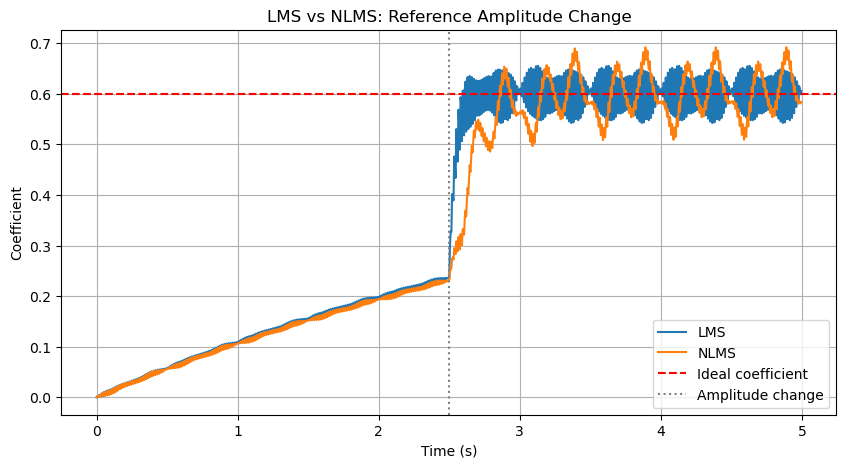

In [28]:
mu = 0.05
epsilon = 1.0     #Increasing epsilon
w = 0.0
y_nlms = np.zeros(N)
e_nlms = np.zeros(N)
w_history_nlms = np.zeros(N)

for n in range(N):
    y_nlms[n] = w * x_ref[n]
    e_nlms[n] = d[n] - y_nlms[n]
    w = w + (mu * e_nlms[n] * x_ref[n]) / (epsilon + x_ref[n] ** 2)
    w_history_nlms[n] = w

plt.figure(figsize=(10, 5))
plt.plot(t, w_history_lms, label="LMS")
plt.plot(t, w_history_nlms, label="NLMS")
plt.axhline(0.6, color="red", linestyle="--",
            label="Ideal coefficient")
plt.axvline(2.5, color="gray", linestyle=":",
            label="Amplitude change")
plt.xlabel("Time (s)")
plt.ylabel("Coefficient")
plt.title("LMS vs NLMS: Reference Amplitude Change")
plt.legend()
plt.grid(True)
plt.show()

So, here I have learned another trade-off:

    increasing epsilon reduces the update magnitude, which can improve smoothness but slow adaptation

conclusion: 

    NLMS is not automatically better than LMS

In [31]:
periods = [("Before amplitude change", 1.5, 2.5), ("After amplitude change", 3.0, 5.0)]
for name, start, end in periods:
    mask = (t >= start) & (t <= end)
    rmse_lms = np.sqrt(np.mean((e_lms[mask] - clean[mask]) ** 2))
    rmse_nlms = np.sqrt(np.mean((e_nlms[mask] - clean[mask]) ** 2))
    print(name)
    print(f"epsilon = 1.0")
    print(f"LMS RMSE = {rmse_lms:.4f}")
    print(f"NLMS RMSE = {rmse_nlms:.4f}\n")
 

Before amplitude change
epsilon = 1.0
LMS RMSE = 0.0570
NLMS RMSE = 0.0576

After amplitude change
epsilon = 1.0
LMS RMSE = 0.0519
NLMS RMSE = 0.0657



### Conclusion:

In this experiment, LMS and NLMS were compared using a reference signal whose amplitude increased from 0.2 to 2.0.

NLMS with epsilon = 0.1 adapted much faster when the reference amplitude was small, but it produced larger coefficient fluctuations after the amplitude increased.

Increasing epsilon to 1.0 reduced these fluctuations, although adaptation became slower. 

The RMSE results showed that neither method was always better. The performance depended on the reference amplitude and the chosen parameters.